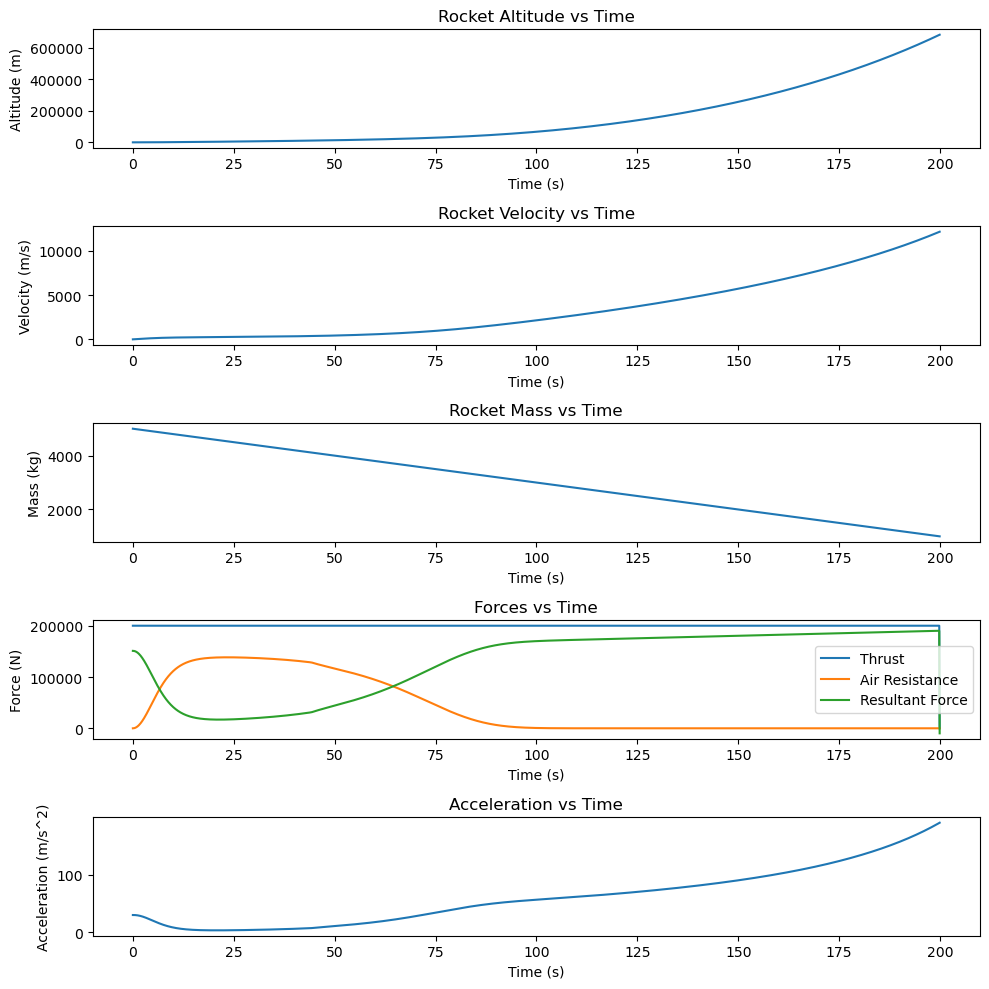

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# Define constants
g = 9.81  # Acceleration due to gravity (m/s^2)
rho_0 = 1.225  # Air density at sea level (kg/m^3)
R = 287.05  # Specific gas constant for air (J/kg.K)
T_0 = 288.15  # Standard temperature (K)
L = 0.0065  # Temperature lapse rate (K/m)
P_0 = 101325  # Sea level pressure (Pa)

# Rocket parameters
initial_mass = 5000  # Initial mass of the rocket (kg)
propellant_mass = 4000  # Mass of the propellant (kg)
thrust = 200000  # Thrust of the rocket engine (N)
burn_rate = 20  # Rate of fuel consumption (kg/s)
Cd = 0.5  # Drag coefficient
A = 10  # Cross-sectional area of the rocket (m^2)

# Simulation parameters
dt = 0.1  # Time step (s)
time = np.arange(0, 200, dt)  # Simulation time array

# Initial conditions
altitude = 0
velocity = 0
mass = initial_mass

# Lists to store results
altitudes = []
velocities = []
masses = []
times = []
thrust_forces = []
drag_forces = []
resultant_forces = []
accelerations = []

# Simulation loop
for t in time:
    # Update atmospheric properties
    if altitude < 11000:  # Troposphere
        T = T_0 - L * altitude
        P = P_0 * (T / T_0) ** (g / (R * L))
    else:  # Above the troposphere, assume constant properties
        T = T_0 - L * 11000
        P = P_0 * (T / T_0) ** (g / (R * L)) * np.exp(-g * (altitude - 11000) / (R * T))

    rho = P / (R * T)  # Air density

    # Compute forces
    drag = 0.5 * Cd * A * rho * velocity**2
    weight = mass * g

    if mass > initial_mass - propellant_mass:  # Engine burning
        acceleration = (thrust - drag - weight) / mass
        mass -= burn_rate * dt
    else:  # Engine cutoff
        acceleration = (-drag - weight) / mass

    # Update state
    velocity += acceleration * dt
    altitude += velocity * dt

    if altitude < 0:  # Rocket has landed
        break

    # Store results
    altitudes.append(altitude)
    velocities.append(velocity)
    masses.append(mass)
    times.append(t)
    thrust_forces.append(thrust if mass > initial_mass - propellant_mass else 0)
    drag_forces.append(drag)
    resultant_forces.append(thrust - drag - weight if mass > initial_mass - propellant_mass else -drag - weight)
    accelerations.append(acceleration)

# Plot results
plt.figure(figsize=(10, 10))

plt.subplot(5, 1, 1)
plt.plot(times, altitudes)
plt.xlabel('Time (s)')
plt.ylabel('Altitude (m)')
plt.title('Rocket Altitude vs Time')

plt.subplot(5, 1, 2)
plt.plot(times, velocities)
plt.xlabel('Time (s)')
plt.ylabel('Velocity (m/s)')
plt.title('Rocket Velocity vs Time')

plt.subplot(5, 1, 3)
plt.plot(times, masses)
plt.xlabel('Time (s)')
plt.ylabel('Mass (kg)')
plt.title('Rocket Mass vs Time')

plt.subplot(5, 1, 4)
plt.plot(times, thrust_forces, label='Thrust')
plt.plot(times, drag_forces, label='Air Resistance')
plt.plot(times, resultant_forces, label='Resultant Force')
plt.xlabel('Time (s)')
plt.ylabel('Force (N)')
plt.title('Forces vs Time')
plt.legend()

plt.subplot(5, 1, 5)
plt.plot(times, accelerations)
plt.xlabel('Time (s)')
plt.ylabel('Acceleration (m/s^2)')
plt.title('Acceleration vs Time')

plt.tight_layout()
plt.show()



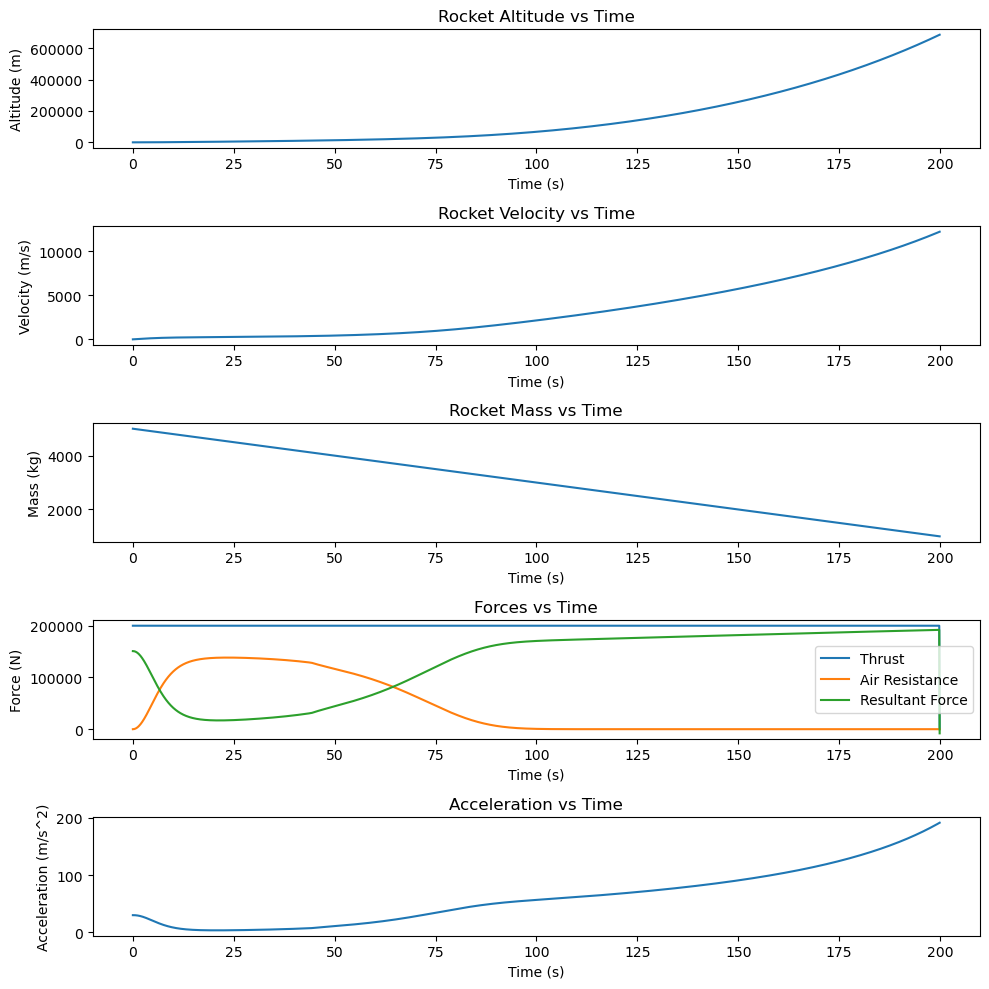

In [3]:
import numpy as np
import matplotlib.pyplot as plt

# Define constants
g = 9.81  # Acceleration due to gravity (m/s^2)
G = 6.67430e-11  # Gravitational constant (m^3 kg^-1 s^-2)
M_earth = 5.972e24  # Mass of the Earth (kg)
R_earth = 6371000  # Radius of the Earth (m)
rho_0 = 1.225  # Air density at sea level (kg/m^3)
R = 287.05  # Specific gas constant for air (J/kg.K)
T_0 = 288.15  # Standard temperature (K)
L = 0.0065  # Temperature lapse rate (K/m)
P_0 = 101325  # Sea level pressure (Pa)

# Rocket parameters
initial_mass = 5000  # Initial mass of the rocket (kg)
propellant_mass = 4000  # Mass of the propellant (kg)
thrust = 200000  # Thrust of the rocket engine (N)
burn_rate = 20  # Rate of fuel consumption (kg/s)
Cd = 0.5  # Drag coefficient
A = 10  # Cross-sectional area of the rocket (m^2)

# Simulation parameters
dt = 0.1  # Time step (s)
time = np.arange(0, 200, dt)  # Simulation time array

# Initial conditions
altitude = 0
velocity = 0
mass = initial_mass

# Lists to store results
altitudes = []
velocities = []
masses = []
times = []
thrust_forces = []
drag_forces = []
resultant_forces = []
accelerations = []

# Simulation loop
for t in time:
    # Update atmospheric properties
    if altitude < 11000:  # Troposphere
        T = T_0 - L * altitude
        P = P_0 * (T / T_0) ** (g / (R * L))
    else:  # Above the troposphere, assume constant properties
        T = T_0 - L * 11000
        P = P_0 * (T / T_0) ** (g / (R * L)) * np.exp(-g * (altitude - 11000) / (R * T))

    rho = P / (R * T)  # Air density

    # Compute forces
    r = R_earth + altitude  # Distance from the Earth's centre
    gravity = G * M_earth / r**2  # Gravitational acceleration at altitude
    drag = 0.5 * Cd * A * rho * velocity**2
    weight = mass * gravity

    if mass > initial_mass - propellant_mass:  # Engine burning
        acceleration = (thrust - drag - weight) / mass
        mass -= burn_rate * dt
    else:  # Engine cutoff
        acceleration = (-drag - weight) / mass

    # Update state
    velocity += acceleration * dt
    altitude += velocity * dt

    if altitude < 0:  # Rocket has landed
        break

    # Store results
    altitudes.append(altitude)
    velocities.append(velocity)
    masses.append(mass)
    times.append(t)
    thrust_forces.append(thrust if mass > initial_mass - propellant_mass else 0)
    drag_forces.append(drag)
    resultant_forces.append(thrust - drag - weight if mass > initial_mass - propellant_mass else -drag - weight)
    accelerations.append(acceleration)

# Plot results
plt.figure(figsize=(10, 10))

plt.subplot(5, 1, 1)
plt.plot(times, altitudes)
plt.xlabel('Time (s)')
plt.ylabel('Altitude (m)')
plt.title('Rocket Altitude vs Time')

plt.subplot(5, 1, 2)
plt.plot(times, velocities)
plt.xlabel('Time (s)')
plt.ylabel('Velocity (m/s)')
plt.title('Rocket Velocity vs Time')

plt.subplot(5, 1, 3)
plt.plot(times, masses)
plt.xlabel('Time (s)')
plt.ylabel('Mass (kg)')
plt.title('Rocket Mass vs Time')

plt.subplot(5, 1, 4)
plt.plot(times, thrust_forces, label='Thrust')
plt.plot(times, drag_forces, label='Air Resistance')
plt.plot(times, resultant_forces, label='Resultant Force')
plt.xlabel('Time (s)')
plt.ylabel('Force (N)')
plt.title('Forces vs Time')
plt.legend()

plt.subplot(5, 1, 5)
plt.plot(times, accelerations)
plt.xlabel('Time (s)')
plt.ylabel('Acceleration (m/s^2)')
plt.title('Acceleration vs Time')

plt.tight_layout()
plt.show()


Initial stored energy: 0.00 J


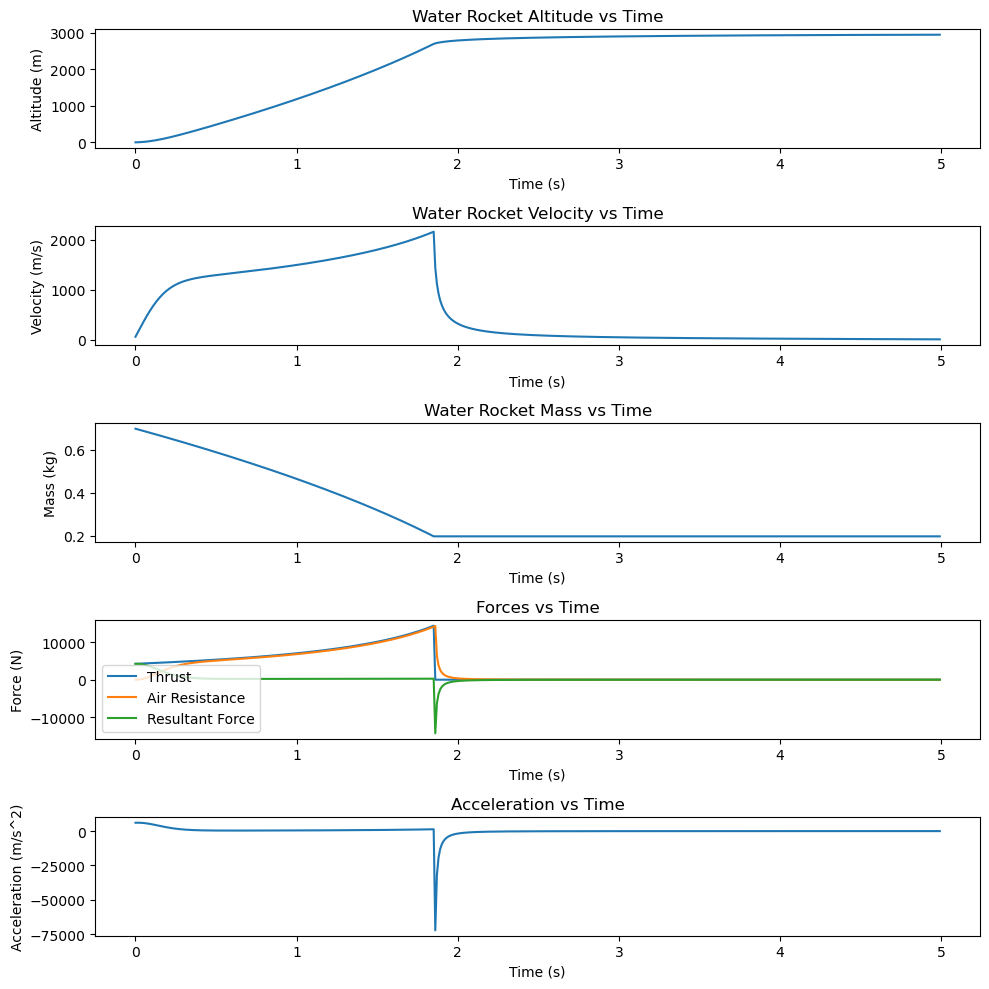

In [4]:
import numpy as np
import matplotlib.pyplot as plt

# Define constants
g = 9.81  # Acceleration due to gravity (m/s^2)
rho_0 = 1.225  # Air density at sea level (kg/m^3)
R = 287.05  # Specific gas constant for air (J/kg.K)
P_atm = 101325  # Atmospheric pressure (Pa)
psi_to_pa = 6894.76  # Conversion factor from psi to Pa

# Water rocket parameters
volume_rocket = 0.001  # Volume of the rocket (m^3, 1 litre)
pressure_max = 120 * psi_to_pa  # Maximum pressure in the air pocket (Pa)
initial_water_volume = 0.0005  # Initial water volume (m^3, half the rocket)
density_water = 1000  # Density of water (kg/m^3)
mass_rocket_empty = 0.2  # Mass of the empty rocket (kg)
Cd = 0.5  # Drag coefficient
A = 0.01  # Cross-sectional area of the rocket (m^2)

# Simulation parameters
dt = 0.01  # Time step (s)
time = np.arange(0, 5, dt)  # Simulation time array

# Initial conditions
altitude = 0
velocity = 0
mass_water = initial_water_volume * density_water
mass = mass_rocket_empty + mass_water
volume_air = volume_rocket - initial_water_volume
pressure_air = pressure_max

# Lists to store results
altitudes = []
velocities = []
masses = []
times = []
thrust_forces = []
drag_forces = []
resultant_forces = []
accelerations = []

# Compute initial stored energy
energy_stored = pressure_max * volume_air * np.log(pressure_max / P_atm) / (pressure_max - P_atm)
print(f"Initial stored energy: {energy_stored:.2f} J")

# Simulation loop
for t in time:
    # Compute forces
    if mass_water > 0:
        # Water ejection phase
        pressure_air = pressure_max * (volume_air / (volume_air + mass_water / density_water)) ** 1.4
        thrust = 2 * A * (pressure_air - P_atm) if pressure_air > P_atm else 0
        mass_water_ejected = thrust * dt / (density_water * np.sqrt(2 * (pressure_air - P_atm) / density_water))
        mass_water -= mass_water_ejected
        mass = mass_rocket_empty + mass_water
    else:
        # Free flight phase
        thrust = 0

    drag = 0.5 * Cd * A * rho_0 * velocity**2
    weight = mass * g
    acceleration = (thrust - drag - weight) / mass

    # Update state
    velocity += acceleration * dt
    altitude += velocity * dt

    if altitude < 0:  # Rocket has landed
        break

    # Store results
    altitudes.append(altitude)
    velocities.append(velocity)
    masses.append(mass)
    times.append(t)
    thrust_forces.append(thrust)
    drag_forces.append(drag)
    resultant_forces.append(thrust - drag - weight)
    accelerations.append(acceleration)

# Plot results
plt.figure(figsize=(10, 10))

plt.subplot(5, 1, 1)
plt.plot(times, altitudes)
plt.xlabel('Time (s)')
plt.ylabel('Altitude (m)')
plt.title('Water Rocket Altitude vs Time')

plt.subplot(5, 1, 2)
plt.plot(times, velocities)
plt.xlabel('Time (s)')
plt.ylabel('Velocity (m/s)')
plt.title('Water Rocket Velocity vs Time')

plt.subplot(5, 1, 3)
plt.plot(times, masses)
plt.xlabel('Time (s)')
plt.ylabel('Mass (kg)')
plt.title('Water Rocket Mass vs Time')

plt.subplot(5, 1, 4)
plt.plot(times, thrust_forces, label='Thrust')
plt.plot(times, drag_forces, label='Air Resistance')
plt.plot(times, resultant_forces, label='Resultant Force')
plt.xlabel('Time (s)')
plt.ylabel('Force (N)')
plt.title('Forces vs Time')
plt.legend()

plt.subplot(5, 1, 5)
plt.plot(times, accelerations)
plt.xlabel('Time (s)')
plt.ylabel('Acceleration (m/s^2)')
plt.title('Acceleration vs Time')

plt.tight_layout()
plt.show()


Initial stored energy: 0.00 J


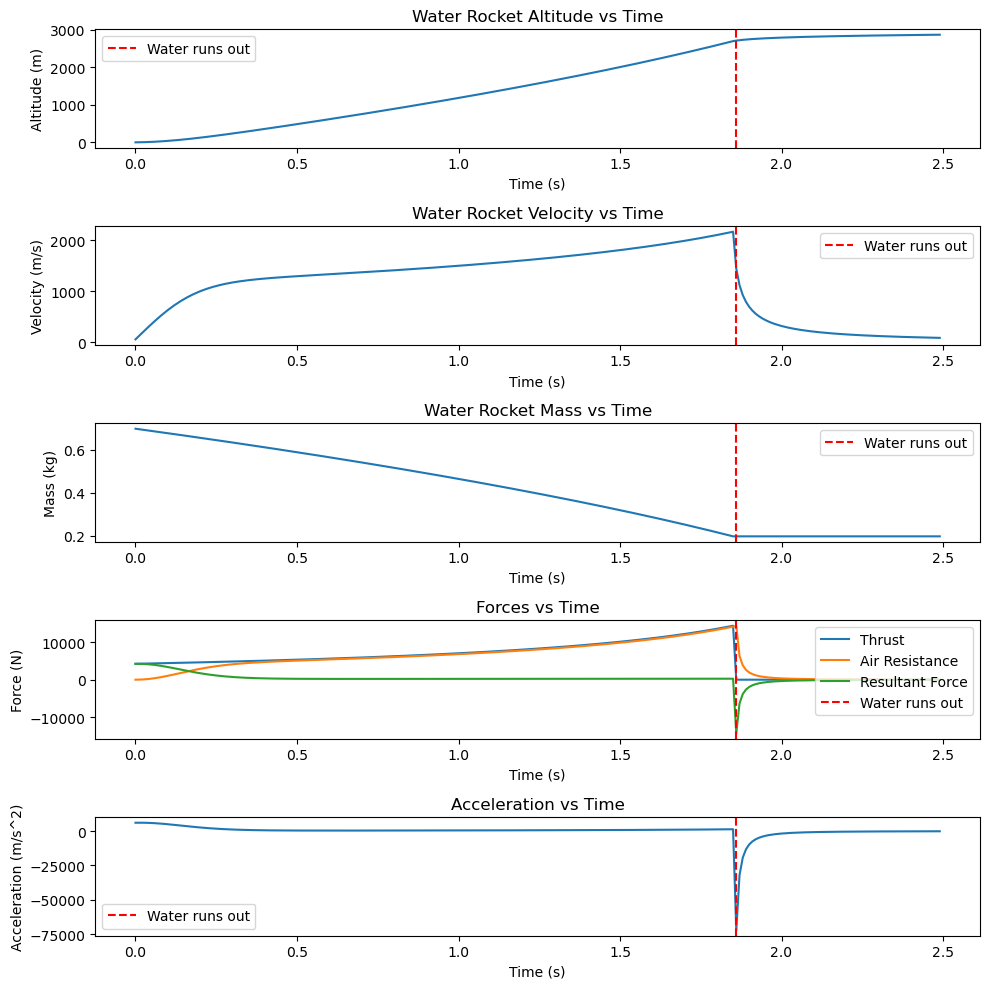

In [8]:
import numpy as np
import matplotlib.pyplot as plt

# Define constants
g = 9.81  # Acceleration due to gravity (m/s^2)
rho_0 = 1.225  # Air density at sea level (kg/m^3)
R = 287.05  # Specific gas constant for air (J/kg.K)
P_atm = 101325  # Atmospheric pressure (Pa)
psi_to_pa = 6894.76  # Conversion factor from psi to Pa

# Water rocket parameters
volume_rocket = 0.001  # Volume of the rocket (m^3, 1 litre)
pressure_max = 120 * psi_to_pa  # Maximum pressure in the air pocket (Pa)
initial_water_volume = 0.0005  # Initial water volume (m^3, half the rocket)
density_water = 1000  # Density of water (kg/m^3)
mass_rocket_empty = 0.2  # Mass of the empty rocket (kg)
Cd = 0.5  # Drag coefficient
A = 0.01  # Cross-sectional area of the rocket (m^2)

# Simulation parameters
dt = 0.01  # Time step (s)
time = np.arange(0, 2.5, dt)  # Simulation time array

# Initial conditions
altitude = 0
velocity = 0
mass_water = initial_water_volume * density_water
mass = mass_rocket_empty + mass_water
volume_air = volume_rocket - initial_water_volume
pressure_air = pressure_max

# Lists to store results
altitudes = []
velocities = []
masses = []
times = []
thrust_forces = []
drag_forces = []
resultant_forces = []
accelerations = []

# Compute initial stored energy
energy_stored = pressure_max * volume_air * np.log(pressure_max / P_atm) / (pressure_max - P_atm)
print(f"Initial stored energy: {energy_stored:.2f} J")

# Simulation loop
water_runout_time = None
for t in time:
    # Compute forces
    if mass_water > 0:
        # Water ejection phase
        pressure_air = pressure_max * (volume_air / (volume_air + mass_water / density_water)) ** 1.4
        thrust = 2 * A * (pressure_air - P_atm) if pressure_air > P_atm else 0
        mass_water_ejected = thrust * dt / (density_water * np.sqrt(2 * (pressure_air - P_atm) / density_water))
        mass_water -= mass_water_ejected
        mass = mass_rocket_empty + mass_water
    else:
        # Free flight phase
        if water_runout_time is None:
            water_runout_time = t
        thrust = 0

    drag = 0.5 * Cd * A * rho_0 * velocity**2
    weight = mass * g
    acceleration = (thrust - drag - weight) / mass

    # Update state
    velocity += acceleration * dt
    altitude += velocity * dt

    if altitude < 0:  # Rocket has landed
        break

    # Store results
    altitudes.append(altitude)
    velocities.append(velocity)
    masses.append(mass)
    times.append(t)
    thrust_forces.append(thrust)
    drag_forces.append(drag)
    resultant_forces.append(thrust - drag - weight)
    accelerations.append(acceleration)

# Plot results
plt.figure(figsize=(10, 10))

plt.subplot(5, 1, 1)
plt.plot(times, altitudes)
if water_runout_time:
    plt.axvline(water_runout_time, linestyle='--', color='red', label='Water runs out')
plt.xlabel('Time (s)')
plt.ylabel('Altitude (m)')
plt.title('Water Rocket Altitude vs Time')
plt.legend()

plt.subplot(5, 1, 2)
plt.plot(times, velocities)
if water_runout_time:
    plt.axvline(water_runout_time, linestyle='--', color='red', label='Water runs out')
plt.xlabel('Time (s)')
plt.ylabel('Velocity (m/s)')
plt.title('Water Rocket Velocity vs Time')
plt.legend()

plt.subplot(5, 1, 3)
plt.plot(times, masses)
if water_runout_time:
    plt.axvline(water_runout_time, linestyle='--', color='red', label='Water runs out')
plt.xlabel('Time (s)')
plt.ylabel('Mass (kg)')
plt.title('Water Rocket Mass vs Time')
plt.legend()

plt.subplot(5, 1, 4)
plt.plot(times, thrust_forces, label='Thrust')
plt.plot(times, drag_forces, label='Air Resistance')
plt.plot(times, resultant_forces, label='Resultant Force')
if water_runout_time:
    plt.axvline(water_runout_time, linestyle='--', color='red', label='Water runs out')
plt.xlabel('Time (s)')
plt.ylabel('Force (N)')
plt.title('Forces vs Time')
plt.legend()

plt.subplot(5, 1, 5)
plt.plot(times, accelerations)
if water_runout_time:
    plt.axvline(water_runout_time, linestyle='--', color='red', label='Water runs out')
plt.xlabel('Time (s)')
plt.ylabel('Acceleration (m/s^2)')
plt.title('Acceleration vs Time')
plt.legend()

plt.tight_layout()
plt.show()


Initial stored energy: 1034.21 J


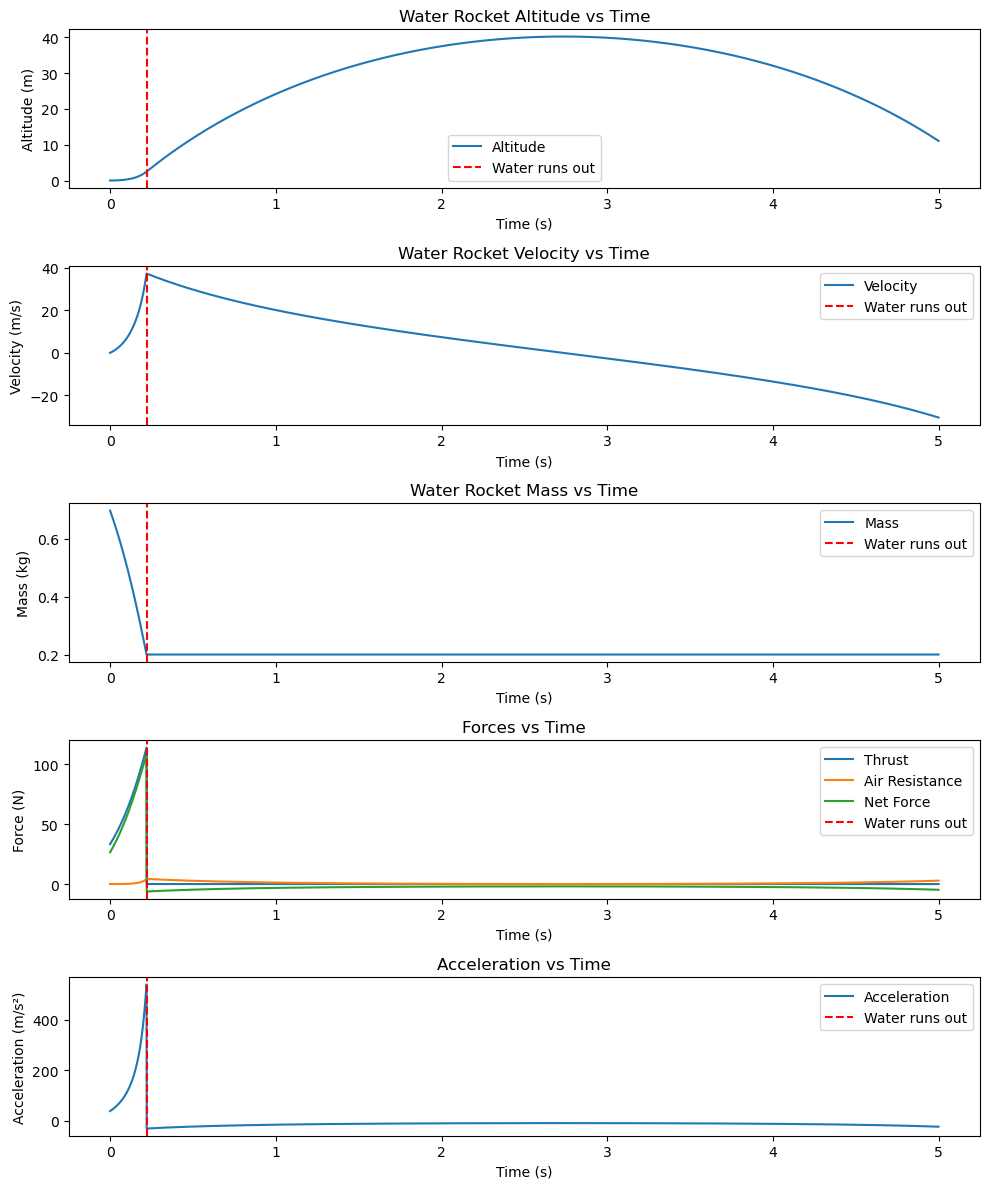

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# Define constants
g = 9.81  # Acceleration due to gravity (m/s^2)
rho_0 = 1.225  # Air density at sea level (kg/m^3)
P_atm = 101325  # Atmospheric pressure (Pa)
psi_to_pa = 6894.76  # Conversion factor from psi to Pa
gamma = 1.4  # Adiabatic index for air

# Water rocket parameters
volume_rocket = 0.001  # Total volume of the rocket (m^3, 1 litre)
pressure_max = 120 * psi_to_pa  # Maximum pressure in the air pocket (Pa)
initial_water_volume = 0.0005  # Initial water volume (m^3, half the rocket)
density_water = 1000  # Density of water (kg/m^3)
mass_rocket_empty = 0.2  # Mass of the empty rocket (kg)
Cd = 0.5  # Drag coefficient
A = 0.01  # Cross-sectional area of the rocket (m^2)
nozzle_diameter = 0.01  # Nozzle diameter (m)
nozzle_area = np.pi * (nozzle_diameter / 2) ** 2  # Nozzle cross-sectional area (m^2)

# Simulation parameters
dt = 0.001  # Time step (s)
time = np.arange(0, 5, dt)  # Simulation time array

# Initial conditions
altitude = 0
velocity = 0
mass_water = initial_water_volume * density_water
mass = mass_rocket_empty + mass_water
volume_air = volume_rocket - initial_water_volume
pressure_air = pressure_max

# Lists to store results
altitudes = []
velocities = []
masses = []
thrust_forces = []
drag_forces = []
resultant_forces = []
accelerations = []
times = []

# Compute initial stored energy
energy_stored = (pressure_max * volume_air) / (gamma - 1)
print(f"Initial stored energy: {energy_stored:.2f} J")

# Simulation loop
water_runout_time = None
for t in time:
    if mass_water > 0:
        # Water ejection phase
        pressure_air = pressure_max * (volume_air / (volume_air + mass_water / density_water)) ** gamma
        if pressure_air > P_atm:
            # Calculate exit velocity using Bernoulli's principle
            water_exit_velocity = np.sqrt(2 * (pressure_air - P_atm) / density_water)
            # Mass flow rate
            mass_flow_rate = density_water * nozzle_area * water_exit_velocity
            # Thrust
            thrust = mass_flow_rate * water_exit_velocity
            # Update water mass
            mass_water -= mass_flow_rate * dt
            if mass_water < 0:
                mass_water = 0
            # Update air volume
            volume_air = volume_rocket - (mass_water / density_water)
            # Update total mass
            mass = mass_rocket_empty + mass_water
        else:
            thrust = 0
    else:
        # Free flight phase
        if water_runout_time is None:
            water_runout_time = t
        thrust = 0

    # Calculate drag force
    drag = 0.5 * Cd * A * rho_0 * velocity**2
    # Calculate net force
    net_force = thrust - drag - (mass * g)
    # Calculate acceleration
    acceleration = net_force / mass

    # Update velocity and altitude
    velocity += acceleration * dt
    altitude += velocity * dt

    if altitude < 0:  # Rocket has landed
        break

    # Store results
    altitudes.append(altitude)
    velocities.append(velocity)
    masses.append(mass)
    thrust_forces.append(thrust)
    drag_forces.append(drag)
    resultant_forces.append(net_force)
    accelerations.append(acceleration)
    times.append(t)

# Plot results
plt.figure(figsize=(10, 12))

plt.subplot(5, 1, 1)
plt.plot(times, altitudes, label='Altitude')
if water_runout_time:
    plt.axvline(water_runout_time, linestyle='--', color='red', label='Water runs out')
plt.xlabel('Time (s)')
plt.ylabel('Altitude (m)')
plt.title('Water Rocket Altitude vs Time')
plt.legend()

plt.subplot(5, 1, 2)
plt.plot(times, velocities, label='Velocity')
if water_runout_time:
    plt.axvline(water_runout_time, linestyle='--', color='red', label='Water runs out')
plt.xlabel('Time (s)')
plt.ylabel('Velocity (m/s)')
plt.title('Water Rocket Velocity vs Time')
plt.legend()

plt.subplot(5, 1, 3)
plt.plot(times, masses, label='Mass')
if water_runout_time:
    plt.axvline(water_runout_time, linestyle='--', color='red', label='Water runs out')
plt.xlabel('Time (s)')
plt.ylabel('Mass (kg)')
plt.title('Water Rocket Mass vs Time')
plt.legend()

plt.subplot(5, 1, 4)
plt.plot(times, thrust_forces, label='Thrust')
plt.plot(times, drag_forces, label='Air Resistance')
plt.plot(times, resultant_forces, label='Net Force')
if water_runout_time:
    plt.axvline(water_runout_time, linestyle='--', color='red', label='Water runs out')
plt.xlabel('Time (s)')
plt.ylabel('Force (N)')
plt.title('Forces vs Time')
plt.legend()

plt.subplot(5, 1, 5)
plt.plot(times, accelerations, label='Acceleration')
if water_runout_time:
    plt.axvline(water_runout_time, linestyle='--', color='red', label='Water runs out')
plt.xlabel('Time (s)')
plt.ylabel('Acceleration (m/s²)')
plt.title('Acceleration vs Time')
plt.legend()

# Adjust spacing between subplots
plt.subplots_adjust(hspace=0.5)  # Increase hspace to add more vertical space between subplots

plt.tight_layout()
plt.show()


Initial stored energy: 1034.21 J


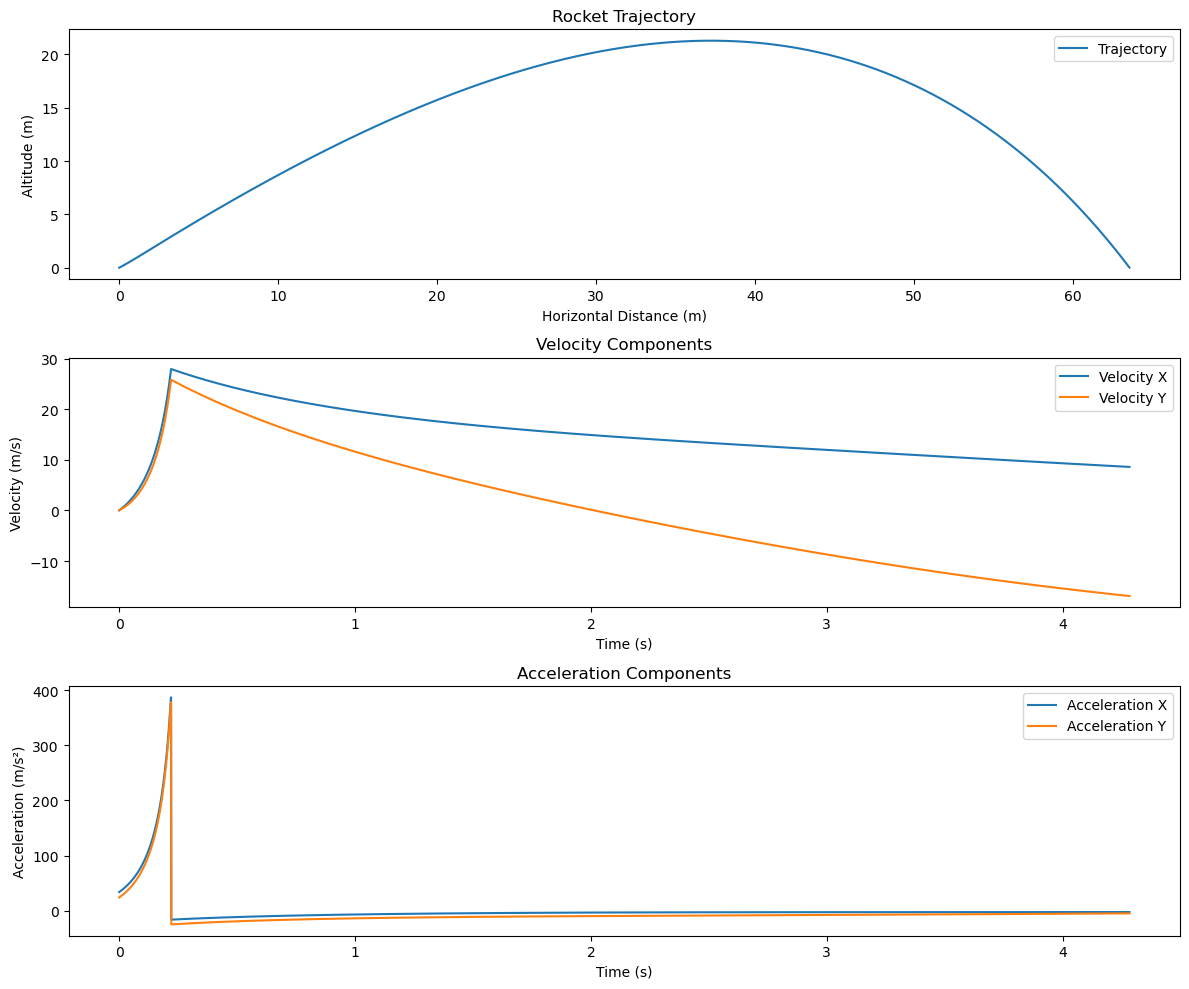

In [5]:
import numpy as np
import matplotlib.pyplot as plt

# Define constants
g = 9.81  # Acceleration due to gravity (m/s^2)
rho_0 = 1.225  # Air density at sea level (kg/m^3)
P_atm = 101325  # Atmospheric pressure (Pa)
psi_to_pa = 6894.76  # Conversion factor from psi to Pa
gamma = 1.4  # Adiabatic index for air

# Water rocket parameters
volume_rocket = 0.001  # Total volume of the rocket (m^3, 1 litre)
pressure_max = 120 * psi_to_pa  # Maximum pressure in the air pocket (Pa)
initial_water_volume = 0.0005  # Initial water volume (m^3, half the rocket)
density_water = 1000  # Density of water (kg/m^3)
mass_rocket_empty = 0.2  # Mass of the empty rocket (kg)
Cd = 0.5  # Drag coefficient
A = 0.01  # Cross-sectional area of the rocket (m^2)
nozzle_diameter = 0.01  # Nozzle diameter (m)
nozzle_area = np.pi * (nozzle_diameter / 2) ** 2  # Nozzle cross-sectional area (m^2)

# Launch parameters
launch_angle = np.radians(45)  # Convert angle to radians

dt = 0.001  # Time step (s)
time = np.arange(0, 5, dt)  # Simulation time array

# Initial conditions
x_pos = 0
altitude = 0
velocity_x = 0
velocity_y = 0
mass_water = initial_water_volume * density_water
mass = mass_rocket_empty + mass_water
volume_air = volume_rocket - initial_water_volume
pressure_air = pressure_max

# Lists to store results
x_positions = []
altitudes = []
velocities_x = []
velocities_y = []
thrust_forces = []
drag_forces = []
accelerations_x = []
accelerations_y = []
times = []

# Compute initial stored energy
energy_stored = (pressure_max * volume_air) / (gamma - 1)
print(f"Initial stored energy: {energy_stored:.2f} J")

# Simulation loop
water_runout_time = None
for t in time:
    if mass_water > 0:
        # Water ejection phase
        pressure_air = pressure_max * (volume_air / (volume_air + mass_water / density_water)) ** gamma
        if pressure_air > P_atm:
            water_exit_velocity = np.sqrt(2 * (pressure_air - P_atm) / density_water)
            mass_flow_rate = density_water * nozzle_area * water_exit_velocity
            thrust = mass_flow_rate * water_exit_velocity
            mass_water -= mass_flow_rate * dt
            if mass_water < 0:
                mass_water = 0
            volume_air = volume_rocket - (mass_water / density_water)
            mass = mass_rocket_empty + mass_water
        else:
            thrust = 0
    else:
        if water_runout_time is None:
            water_runout_time = t
        thrust = 0

    # Resolve forces into x and y components
    thrust_x = thrust * np.cos(launch_angle)
    thrust_y = thrust * np.sin(launch_angle)

    # Drag force calculation
    velocity = np.sqrt(velocity_x**2 + velocity_y**2)
    drag = 0.5 * Cd * A * rho_0 * velocity**2 if velocity > 0 else 0
    drag_x = drag * (velocity_x / velocity) if velocity > 0 else 0
    drag_y = drag * (velocity_y / velocity) if velocity > 0 else 0

    # Net forces
    net_force_x = thrust_x - drag_x
    net_force_y = thrust_y - drag_y - (mass * g)

    # Acceleration calculations
    acceleration_x = net_force_x / mass
    acceleration_y = net_force_y / mass

    # Update velocities and positions
    velocity_x += acceleration_x * dt
    velocity_y += acceleration_y * dt
    x_pos += velocity_x * dt
    altitude += velocity_y * dt

    if altitude < 0:
        break  # Rocket has landed

    # Store results
    x_positions.append(x_pos)
    altitudes.append(altitude)
    velocities_x.append(velocity_x)
    velocities_y.append(velocity_y)
    thrust_forces.append(thrust)
    drag_forces.append(drag)
    accelerations_x.append(acceleration_x)
    accelerations_y.append(acceleration_y)
    times.append(t)

# Plot results
plt.figure(figsize=(12, 10))

plt.subplot(3, 1, 1)
plt.plot(x_positions, altitudes, label='Trajectory')
plt.xlabel('Horizontal Distance (m)')
plt.ylabel('Altitude (m)')
plt.title('Rocket Trajectory')
plt.legend()

plt.subplot(3, 1, 2)
plt.plot(times, velocities_x, label='Velocity X')
plt.plot(times, velocities_y, label='Velocity Y')
plt.xlabel('Time (s)')
plt.ylabel('Velocity (m/s)')
plt.title('Velocity Components')
plt.legend()

plt.subplot(3, 1, 3)
plt.plot(times, accelerations_x, label='Acceleration X')
plt.plot(times, accelerations_y, label='Acceleration Y')
plt.xlabel('Time (s)')
plt.ylabel('Acceleration (m/s²)')
plt.title('Acceleration Components')
plt.legend()

plt.tight_layout()
plt.show()

